In [45]:
# علياء فارس مصطفى احمد     20242449 
# 20240407     عهد أشرف عبد الغني محمد 

#Task 1

In [46]:
import numpy as np
from sklearn.datasets import load_breast_cancer
np.random.seed(42)

def train_test_split(x, y, test_size=0.2, seed=42):
    rng = np.random.RandomState(seed)
    train_idx, test_idx = [], []
    for i in np.unique(y):
        idx = np.where(y == i)[0]
        rng.shuffle(idx)
        n_test = int(round(len(idx) * test_size))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    train_idx = np.array(train_idx); test_idx = np.array(test_idx)
    rng.shuffle(train_idx); rng.shuffle(test_idx)
    return x[train_idx], x[test_idx], y[train_idx], y[test_idx]

data = load_breast_cancer()
x, y = data.data, data.target
x_train, x_test, y_train, y_test = train_test_split(x, y)
for name, labels in [("full", y), ("train", y_train), ("test", y_test)]:
    classes, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(classes, counts)),"| ratio:", np.round(counts / len(labels), 3),
    "| percentage:", np.round(counts / len(labels) * 100, 2), "%")

full {np.int64(0): np.int64(212), np.int64(1): np.int64(357)} | ratio: [0.373 0.627] | percentage: [37.26 62.74] %
train {np.int64(0): np.int64(170), np.int64(1): np.int64(286)} | ratio: [0.373 0.627] | percentage: [37.28 62.72] %
test {np.int64(0): np.int64(42), np.int64(1): np.int64(71)} | ratio: [0.372 0.628] | percentage: [37.17 62.83] %


In [47]:
# Task2:
#I implemented the Gaussian Naive Bayes from scratch.
#In the train function I calculated the mean, variance and prior probability for each class.
#I also added variance smoothing to avoid division by zero.
#In predict_proba, I used log probabilities to calculate the final class probabilities.
#I also created a tiny dataset to test the calculations and compare the results with the manual calculations.
#For the sanity test, I created a tiny dataset with 2 classes and 1 feature. I used 3 values for each class:
#Class 0: 25.380, 24.990, 23.570 and Class 1: 15.110, 14.500, 10.230
#I chose feature worst radius.
#I used 23.570 as the test value to calculate the likelihood and posterior probability for both classes. 
#Then, I compared the manual calculations with my GNB results using np.allclose.

In [48]:
X = np.array([[25.380],[24.990],[23.570],[15.110],[14.500],[10.230]])
y = np.array([0, 0, 0, 1, 1, 1])

class_0 = np.array([25.380, 24.990, 23.570])
class_1 = np.array([15.110, 14.500, 10.230])

mean_0 = np.sum(class_0)/ len(class_0)
difference_0 = class_0 - mean_0
square_0 = difference_0 ** 2
variance_0 = np.sum(square_0) / len(class_0)
var_smoothing = 1e-9
epsilon = var_smoothing * np.max(np.var(X, axis=0))
variance_0 = variance_0 + epsilon
prior_0 = len(class_0) / 6
x_value = 23.570
likelihood_0 = (1 / np.sqrt(2 * np.pi * variance_0)) * np.exp(-(x_value - mean_0) ** 2 / (2 * variance_0))

mean_1 = np.sum(class_1)/ len(class_1)
difference_1 = class_1 - mean_1
square_1 = difference_1 ** 2
variance_1 = np.sum(square_1) / len(class_1)
variance_1 = variance_1 + epsilon
prior_1 = len(class_1) / 6
x_value = 23.570
likelihood_1 = (1 / np.sqrt(2 * np.pi * variance_1)) * np.exp(-(x_value - mean_1) ** 2 / (2 * variance_1))
posterior_0 = (likelihood_0 *prior_0) / (likelihood_0 *prior_0 + likelihood_1 *prior_1)
posterior_1 = (likelihood_1 * prior_1) / (likelihood_0 *prior_0 + likelihood_1 *prior_1)

print("Class0 Mean:", mean_0)
print("Class0 Variance:", variance_0)
print("Prior0:", prior_0)
print("Likelihood0:", likelihood_0)
print("Posterior0:", posterior_0)

print("\nClass1 Mean:", mean_1)
print("Class1 Variance:", variance_1)
print("Prior1:", prior_1)
print("Likelihood1:", likelihood_1)
print("Posterior1:", posterior_1)

class GaussianNaiveBayes:
    def train(self, X, y):
        self.classes = np.unique(y)
        means = []
        variances = []
        priors = []
        var_smoothing = 1e-9
        epsilon = var_smoothing * np.max(np.var(X, axis=0))
        for c in self.classes:
            X_class = X[y == c]
            mean = np.sum(X_class, axis=0) / len(X_class)
            difference = X_class - mean
            square = difference ** 2
            variance = np.sum(square, axis=0) / len(X_class)
            variance = variance + epsilon
            prior = len(X_class) / len(y)

            means.append(mean)
            variances.append(variance)
            priors.append(prior)
        self.means = np.array(means)
        self.variances = np.array(variances)
        self.priors = np.array(priors)

    def predict_proba(self, x):
        x = np.array(x)
        if len(x.shape) == 1:
            x =np.array([x])

        probabilities = []
        for i in range(len(self.classes)):
            mean = self.means[i]
            variance = self.variances[i]
            prior = self.priors[i]
            likelihood = -0.5 * np.sum(np.log(2 * np.pi * variance)+ (x - mean) ** 2 / variance,axis=1)
            posterior = np.log(prior) + likelihood
            probabilities.append(posterior)

        probabilities = np.array(probabilities).T
        probabilities = np.exp(probabilities - np.max(probabilities, axis=1, keepdims=True))
        probabilities = probabilities / np.sum(probabilities, axis=1, keepdims=True)
        return probabilities
    def predict(self, x):
        proba = self.predict_proba(x)
        return self.classes[np.argmax(proba, axis=1)]

GNB = GaussianNaiveBayes()
GNB.train(X, y)
posterior = GNB.predict_proba([23.570])
print("\nClass0 Mean:", GNB.means[0])
print("Class0 Variance:", GNB.variances[0])
print("Prior0:", GNB.priors[0])
print("Posterior0:", posterior[0][0])
print("Class1 Mean:", GNB.means[1])
print("Class1 Variance:", GNB.variances[1])
print("Prior1:", GNB.priors[1])
print("Posterior1:", posterior[0][1])

   
print(np.allclose(mean_0, GNB.means[0][0]))
print(np.allclose(variance_0, GNB.variances[0][0]))
print(np.allclose(mean_1, GNB.means[1][0]))
print(np.allclose(variance_1, GNB.variances[1][0]))
print(np.allclose(posterior_0, posterior[0][0]))
print(np.allclose(posterior_1, posterior[0][1]))

Class0 Mean: 24.646666666666665
Class0 Variance: 0.6049555905149434
Prior0: 0.5
Likelihood0: 0.19676710471474396
Posterior0: 0.9999876390325416

Class1 Mean: 13.280000000000001
Class1 Variance: 4.713266701626054
Prior1: 0.5
Likelihood1: 2.432261843387486e-06
Posterior1: 1.236096745847854e-05

Class0 Mean: [24.64666667]
Class0 Variance: [0.60495559]
Prior0: 0.5
Posterior0: 0.9999876390325416
Class1 Mean: [13.28]
Class1 Variance: [4.7132667]
Prior1: 0.5
Posterior1: 1.2360967458478559e-05
True
True
True
True
True
True


In [49]:
# Task 3:
# I implemented the evaluation metrics from scratch.
# Accuracy: Measures how many predictions are correct.
# Confusion Matrix: Shows the correct and wrong predictions for each class.
# Precision: Measures how many predicted samples for a class are actually correct.
# Recall: Measures how many actual samples of a class were correctly predicted.
# F1-score: Combines precision and recall into one score.
# I also calculated the macro average for precision, recall, and F1-score.
# I tested the model on both the small dataset and the Breast Cancer dataset
# and displayed the confusion matrices as heatmaps.

Tiny Dataset
Accuracy: 1.0
Confusion Matrix:
[[1 0]
 [0 1]]
Precision: [1.0, 1.0]
Recall: [1.0, 1.0]
F1: [1.0, 1.0]
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0

Tiny Dataset Confusion Matrix


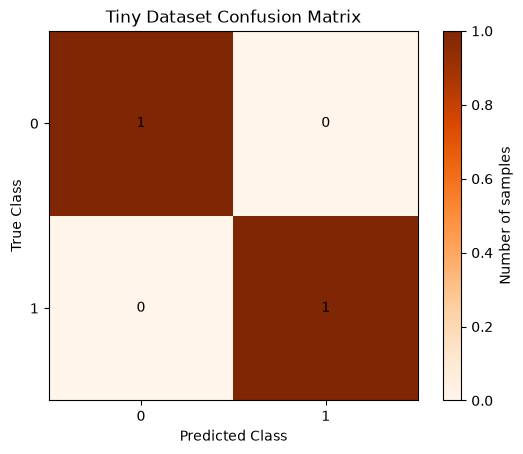


Large Dataset
Accuracy: 0.9380530973451328
Confusion Matrix:
[[40  2]
 [ 5 66]]
Precision: [0.8888888888888888, 0.9705882352941176]
Recall: [0.9523809523809523, 0.9295774647887324]
F1: [0.9195402298850575, 0.9496402877697842]
Macro Precision: 0.9297385620915033
Macro Recall: 0.9409792085848423
Macro F1: 0.9345902588274209

Large Dataset Confusion Matrix


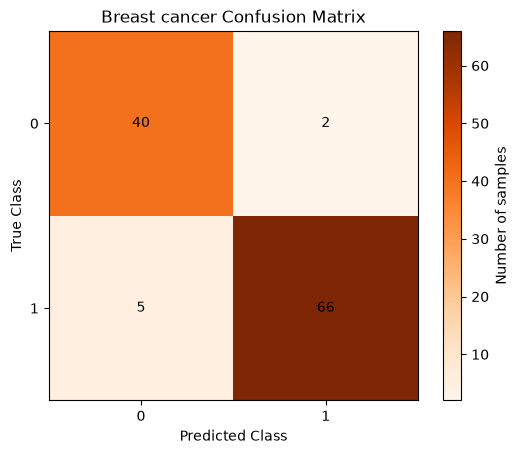

In [50]:
def accuracy(y_true, y_pred):
    result = np.sum(y_true == y_pred)/ len(y_true)
    return result

def confusion_matrix(y_true, y_pred, classes):
    k = len(classes)
    matrix = np.zeros((k, k), dtype=int)
    for i in range(len(y_true)):
        matrix[y_true[i]][y_pred[i]] += 1
    return matrix

def precision_recall_f1(y_true, y_pred, classes):
    matrix = confusion_matrix(y_true, y_pred, classes)
    precision = []
    recall = []
    f1 = []
    for i in range(len(classes)):
        TP = matrix[i][i]
        FP = np.sum(matrix[:, i]) - TP
        FN = np.sum(matrix[i, :]) - TP
        pre = 0
        rec = 0
        f = 0

        if TP + FP != 0:
            pre = TP / (TP + FP)
        if TP + FN != 0:
            rec = TP / (TP + FN)
        if pre + rec != 0:
            f = 2 * pre * rec / (pre + rec)

        precision.append(float(pre))
        recall.append(float(rec))
        f1.append(float(f))
    macro_precision = sum(precision) / len(classes)
    macro_recall = sum(recall) / len(classes)
    macro_f1 = sum(f1) / len(classes)

    return (precision, recall, f1,macro_precision, macro_recall, macro_f1)

import matplotlib.pyplot as plt

def plot_confusion_matrix(matrix, classes, title):
    plt.imshow(matrix, cmap="Oranges")
    plt.colorbar(label="Number of samples")
    plt.xticks(range(len(classes)), classes)
    plt.yticks(range(len(classes)), classes)
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, matrix[i][j], ha="center", va="center")

    plt.show()

# Tiny Dataset
X_train_small, X_test_small, y_train_small, y_test_small = train_test_split(X, y)
GNB_small = GaussianNaiveBayes()
GNB_small.train(X_train_small, y_train_small)
prob_small = GNB_small.predict_proba(X_test_small)
pred_small = GNB_small.classes[np.argmax(prob_small, axis=1)]
confusion_matrix_small = confusion_matrix(y_test_small, pred_small, GNB_small.classes)
precision, recall, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(y_test_small, pred_small, GNB_small.classes)

print("Tiny Dataset")
print("Accuracy:", accuracy(y_test_small, pred_small))
print("Confusion Matrix:")
print(confusion_matrix_small)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("Macro Precision:", macro_p)
print("Macro Recall:", macro_r)
print("Macro F1:", macro_f1)
print("\nTiny Dataset Confusion Matrix")
plot_confusion_matrix(confusion_matrix_small, GNB_small.classes, "Tiny Dataset Confusion Matrix")


# Large Dataset
GNB_large = GaussianNaiveBayes()
GNB_large.train(x_train, y_train)
prob_large = GNB_large.predict_proba(x_test)
pred_large = GNB_large.predict(x_test) 
confusion_matrix_large = confusion_matrix(y_test, pred_large, GNB_large.classes)
precision, recall, f1, macro_p, macro_r, macro_f1 = precision_recall_f1(y_test, pred_large, GNB_large.classes)

print("\nLarge Dataset")
print("Accuracy:", accuracy(y_test, pred_large))
print("Confusion Matrix:")
print(confusion_matrix_large)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("Macro Precision:", macro_p)
print("Macro Recall:", macro_r)
print("Macro F1:", macro_f1)
print("\nLarge Dataset Confusion Matrix")
plot_confusion_matrix(confusion_matrix_large, GNB_large.classes, "Breast cancer Confusion Matrix")

########## Task 1 (scaling question)

In [51]:
mu, sigma = x_train.mean(axis=0), x_train.std(axis=0)
x_train_s = (x_train - mu) / sigma
x_test_s  = (x_test  - mu) / sigma

model_raw = GaussianNaiveBayes()
model_raw.train(x_train, y_train)
pred_raw = model_raw.classes[np.argmax(model_raw.predict_proba(x_test), axis=1)]

model_scaled = GaussianNaiveBayes()
model_scaled.train(x_train_s, y_train)
pred_scaled = model_scaled.classes[np.argmax(model_scaled.predict_proba(x_test_s), axis=1)]

print("Without scaling:", accuracy(y_test, pred_raw), "\nWithout scaling percentage:", accuracy(y_test, pred_raw)*100, "%")
print("With scaling:", accuracy(y_test, pred_scaled), "\nWith scaling percentage:", accuracy(y_test, pred_scaled)*100, "%")

Without scaling: 0.9380530973451328 
Without scaling percentage: 93.80530973451327 %
With scaling: 0.9380530973451328 
With scaling percentage: 93.80530973451327 %


#Task 4

choosen feature:  worst concave points
Copies: 1, Accuracy: 0.9381, Avg Max prob: 0.9994
Copies: 3, Accuracy: 0.9381, Avg Max prob: 0.9996
Copies: 5, Accuracy: 0.9469, Avg Max prob: 0.9954
Copies: 10, Accuracy: 0.9469, Avg Max prob: 0.9962


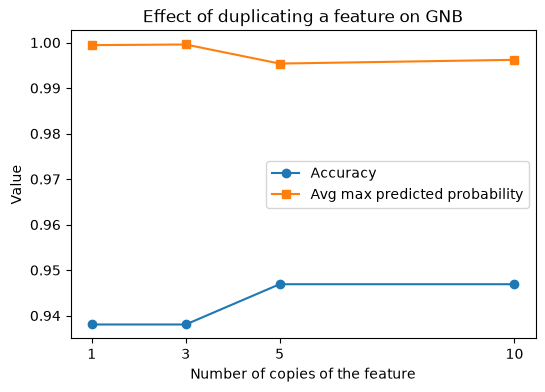

In [52]:
m0, m1 = x_train[y_train == 0].mean(0), x_train[y_train == 1].mean(0)
v0, v1 = x_train[y_train == 0].var(0), x_train[y_train == 1].var(0)
best = np.argmax(np.abs(m0 - m1) / (np.sqrt(v0 + v1)))
print("choosen feature: ", data.feature_names[best])

def duplicate_feature(x, j, n_copies):
    extra = np.repeat(x[:, [j]], n_copies-1, axis=1)
    return np.hstack([x, extra])

copies_list = [1,3,5,10]
accs, confs = [], []

for k in copies_list:
    xtr= duplicate_feature(x_train, best, k)
    xte = duplicate_feature(x_test, best, k)

    model = GaussianNaiveBayes()
    model.train(xtr, y_train)
    proba = model.predict_proba(xte)
    pred = model.classes[np.argmax(proba, axis=1)]
    accs.append(accuracy(y_test, pred))
    confs.append(proba.max(axis=1).mean())
    print(f"Copies: {k}, Accuracy: {accs[-1]:.4f}, Avg Max prob: {confs[-1]:.4f}")


fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(copies_list, accs,  marker='o', label='Accuracy')
ax.plot(copies_list, confs, marker='s', label='Avg max predicted probability')
ax.set_xlabel('Number of copies of the feature')
ax.set_ylabel('Value')
ax.set_title('Effect of duplicating a feature on GNB')
ax.set_xticks(copies_list)
ax.legend()
plt.show() 

#Task 5 

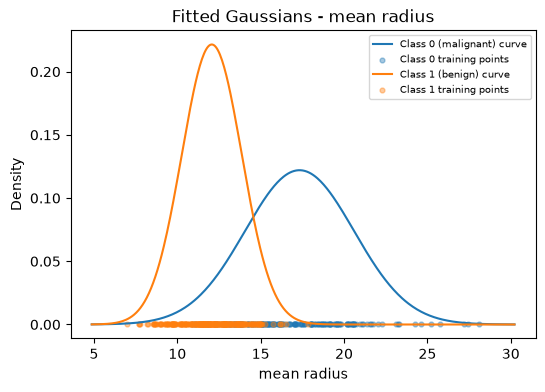

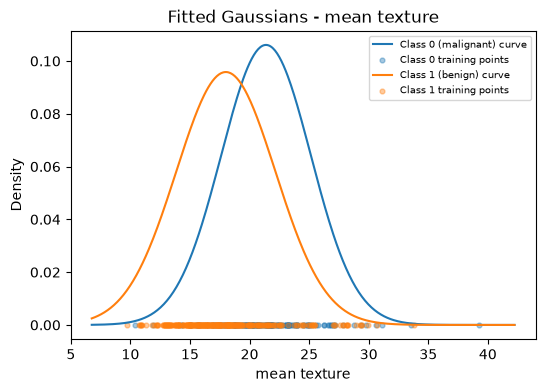

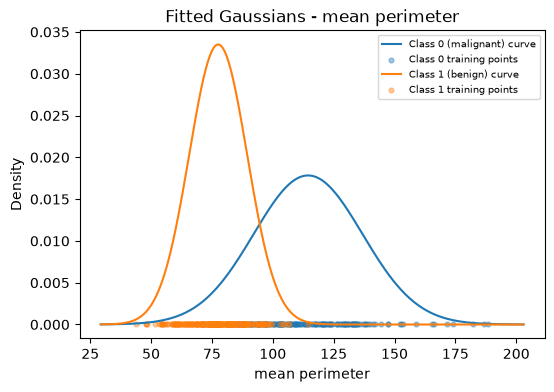

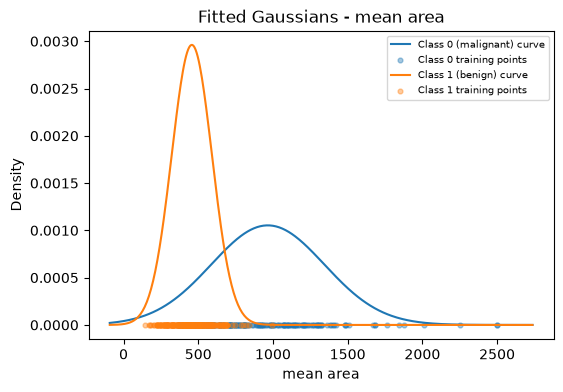

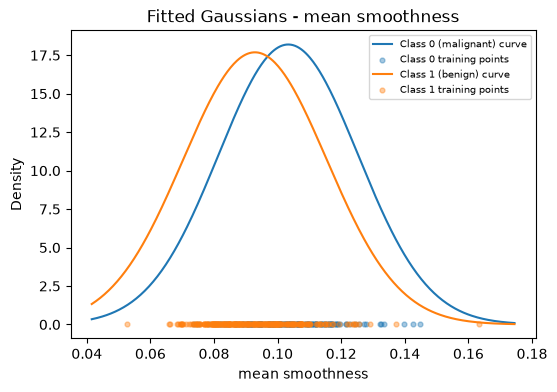

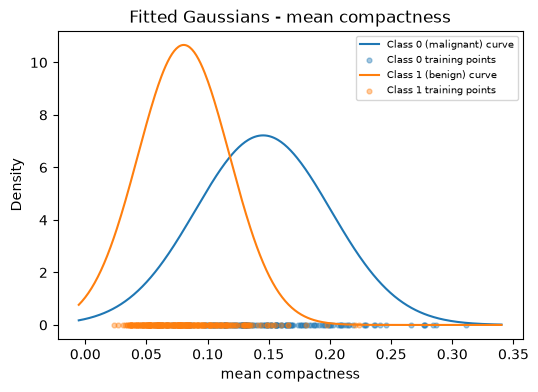

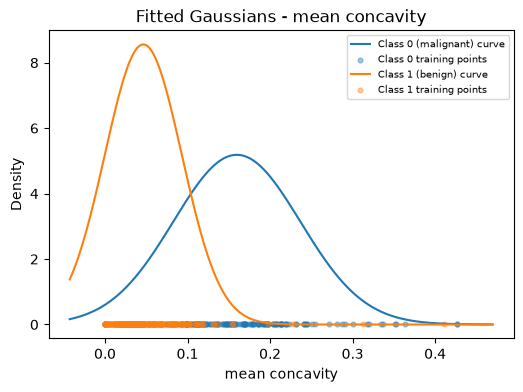

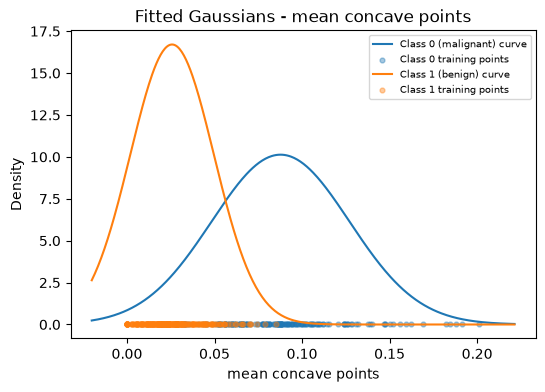

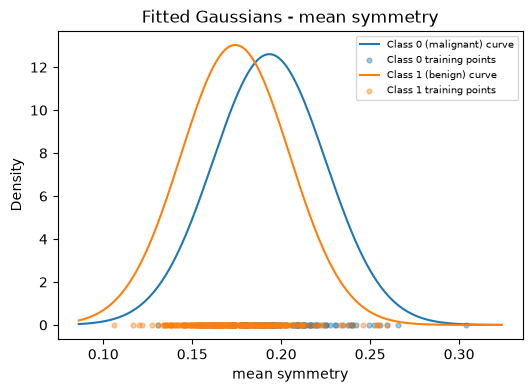

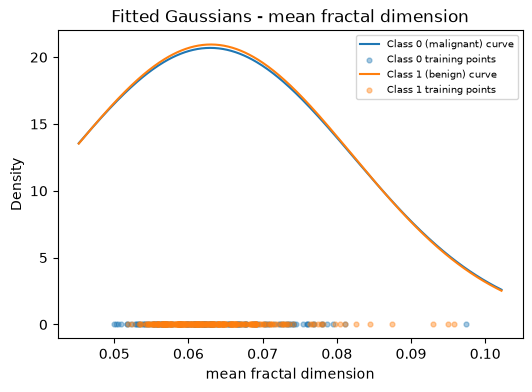

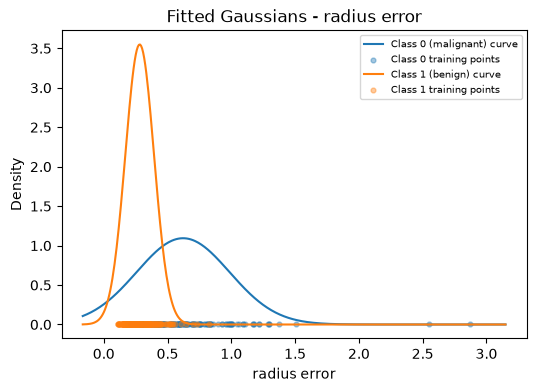

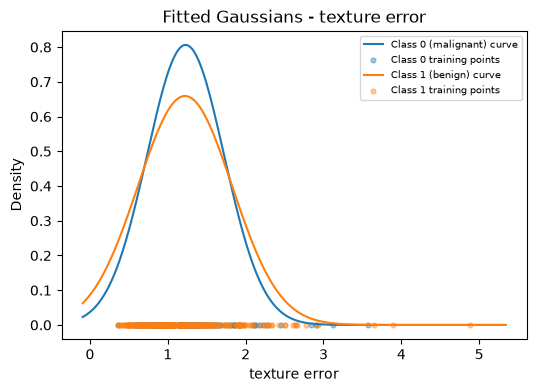

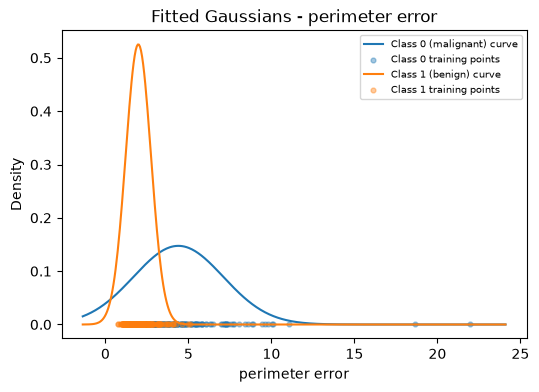

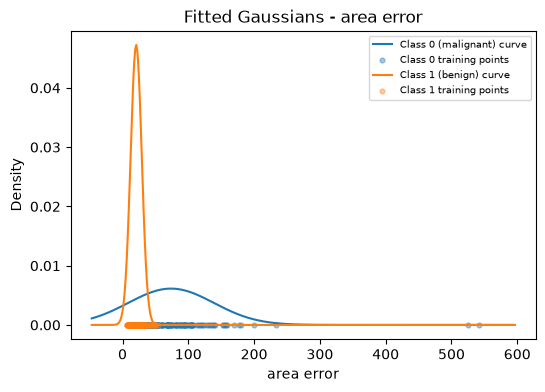

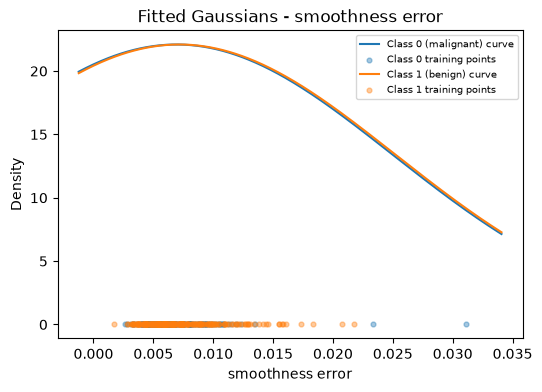

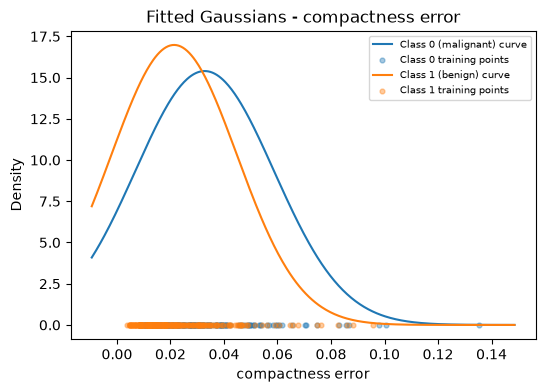

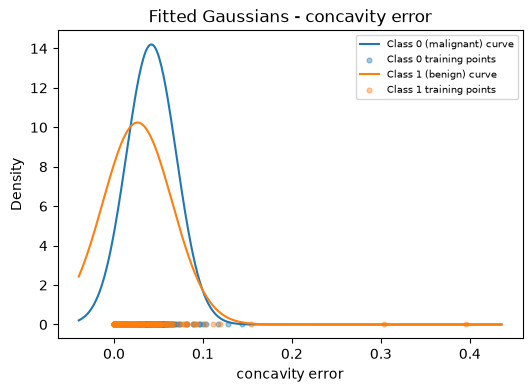

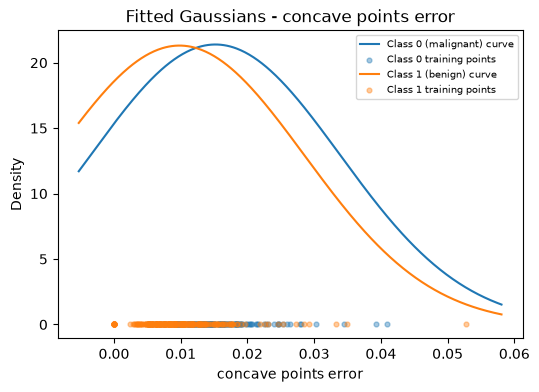

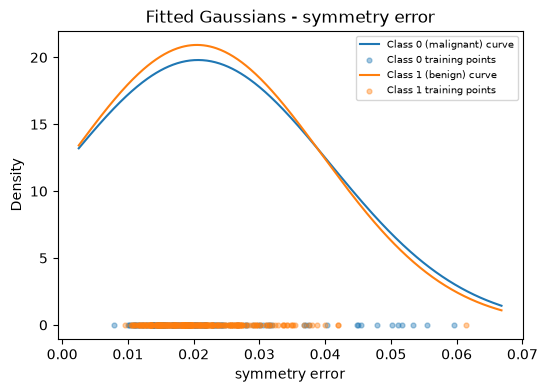

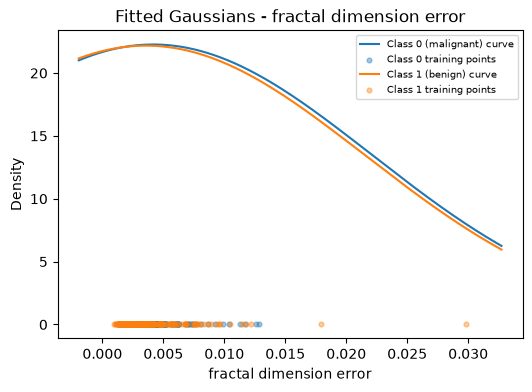

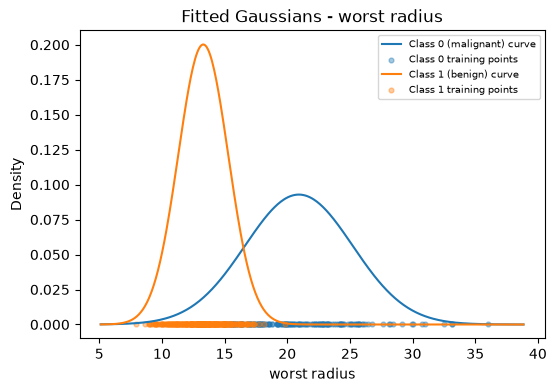

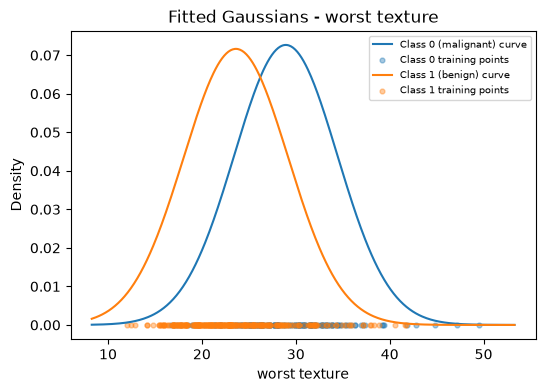

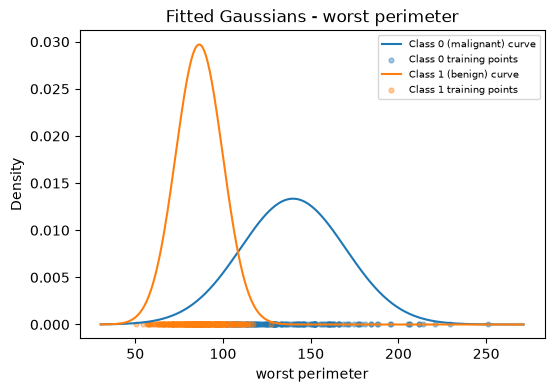

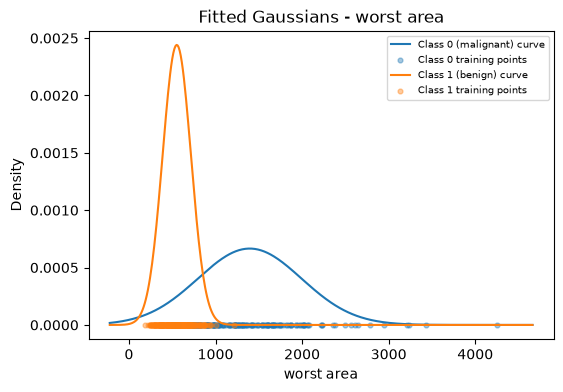

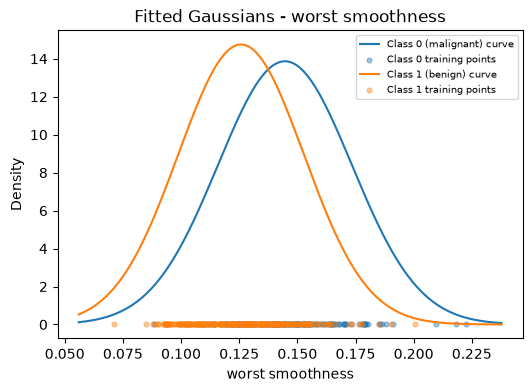

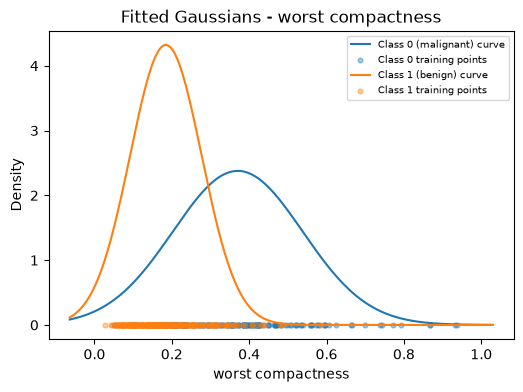

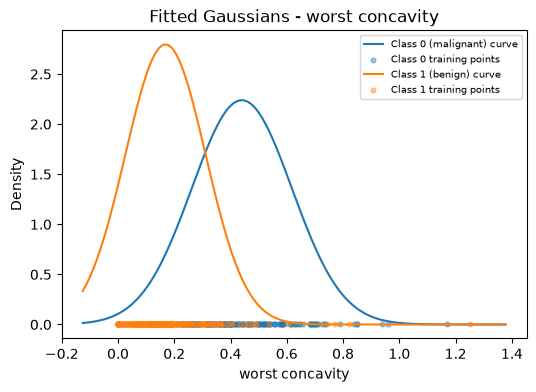

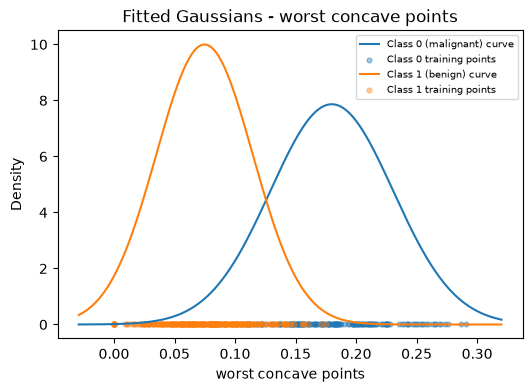

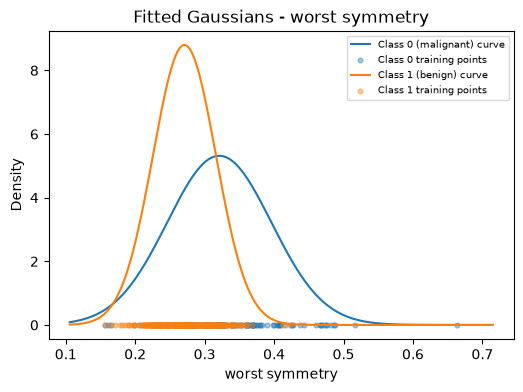

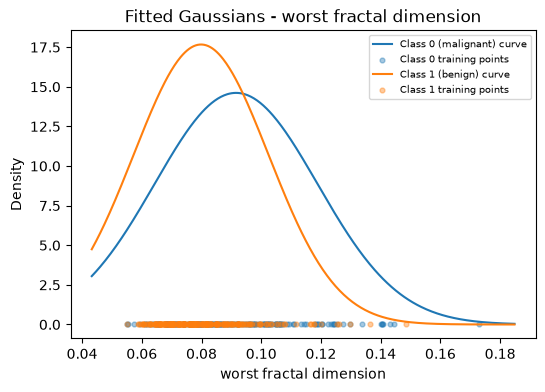

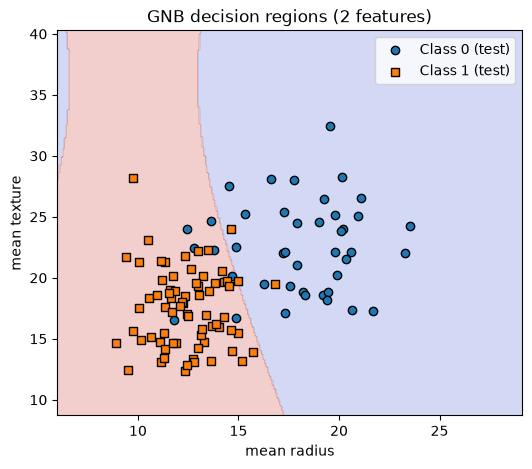

In [53]:
names = list(data.feature_names)

########### Gaussian curve

def plot_gaussians (model, x_tr, y_tr, j, feature_name):
    fig, ax = plt.subplots(figsize=(6, 4))
    lo, hi = x_tr[:, j].min(), x_tr[:, j].max()
    pad = 0.1 * (hi - lo)
    grid = np.linspace(lo - pad, hi + pad, 400)
    labels = {0: "malignant", 1: "benign"}
    for i, c in enumerate(model.classes):
        mu, var = model.means[i][j], model.variances[i][j]
        pdf = np.exp(-(grid - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
        line, = ax.plot(grid, pdf, label=f"Class {c} ({labels[int(c)]}) curve")
        ax.scatter(x_tr[y_tr == c, j], np.zeros((y_tr == c).sum()),
                   s=12, alpha=0.4, color=line.get_color(),
                   label=f"Class {c} training points")
    ax.set_xlabel(feature_name)
    ax.set_ylabel("Density")
    ax.set_title(f"Fitted Gaussians - {feature_name}")
    ax.legend(fontsize=7)
    plt.show()

model_full = GaussianNaiveBayes()
model_full.train(x_train, y_train)
for j, fname in enumerate(names):
    plot_gaussians(model_full, x_train, y_train, j, fname)

########### decision boundary

f1, f2 = names.index("mean radius"), names.index("mean texture")
model_2d = GaussianNaiveBayes()
model_2d.train(x_train[:, [f1, f2]], y_train)

xmin, xmax = x_train[:, f1].min() - 1, x_train[:, f1].max() + 1
ymin, ymax = x_train[:, f2].min() - 1, x_train[:, f2].max() + 1
xx, yy = np.meshgrid(np.linspace(xmin, xmax, 300), np.linspace(ymin, ymax, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = model_2d.classes[np.argmax(model_2d.predict_proba(grid_points), axis=1)].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
for c, m in zip(model_2d.classes, ["o", "s"]):
    ax.scatter(x_test[y_test == c, f1], x_test[y_test == c, f2],
               marker=m, edgecolor="k", label=f"Class {c} (test)")
ax.set_xlabel("mean radius")
ax.set_ylabel("mean texture")
ax.set_title("GNB decision regions (2 features)")
ax.legend()
plt.show()

#Task 6

In [55]:
from sklearn.naive_bayes import GaussianNB

def compare(Xtr, ytr, Xte, name):
    mine = GaussianNaiveBayes()
    mine.train(Xtr, ytr)
    sk = GaussianNB(var_smoothing=1e-9)
    sk.fit(Xtr, ytr)

    print("\n", name)
    print("theta_  :", np.allclose(mine.means, sk.theta_))
    print("var_  :", np.allclose(mine.variances, sk.var_))
    print("class_prior_ :", np.allclose(mine.priors, sk.class_prior_))

    p_mine, p_sk = mine.predict_proba(Xte), sk.predict_proba(Xte)
    print("predict_proba:", np.allclose(p_mine, p_sk))

    pred_mine = mine.classes[np.argmax(p_mine, axis=1)]
    pred_sk = sk.predict(Xte)
    print("Agreement: %.2f%%" % (100 * np.mean(pred_mine == pred_sk)))

compare(X, y, X, "Tiny dataset") 
compare(x_train, y_train, x_test, "Breast Cancer")


 Tiny dataset
theta_  : True
var_  : True
class_prior_ : True
predict_proba: True
Agreement: 100.00%

 Breast Cancer
theta_  : True
var_  : True
class_prior_ : True
predict_proba: True
Agreement: 100.00%
